In [1]:
pip install implicit nltk pymorphy3 sentence-transformers seaborn tqdm matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [ ]:
import os
import re
import json
import pickle
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity


import nltk
from nltk.corpus import stopwords
import pymorphy3
from sentence_transformers import SentenceTransformer

from sklearn.cluster import KMeans

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

OUTPUT_DIR = Path('./output')
OUTPUT_DIR.mkdir(exist_ok=True)

nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Admin\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [3]:
df = pd.read_csv('mproj.csv',
                 encoding='utf-8-sig', sep=',', quotechar='"', on_bad_lines='warn')

print(f"Размер: {df.shape[0]:,} строк × {df.shape[1]} колонок")
print(f"Уникальных material_id: {df['material_id'].nunique():,}")
print(f"Дубликатов: {len(df) - df['material_id'].nunique():,}")

Размер: 60,000 строк × 36 колонок
Уникальных material_id: 60,000
Дубликатов: 0


In [4]:
# 1) duration → int
df['duration_min'] = pd.to_numeric(
    df['material.duration'].astype(str).str.extract(r'(\d+)')[0],
    errors='coerce'
)

# 2) мульти-классы: "7, 8" → frozenset({7, 8})
def parse_grade_set(s: str) -> frozenset:
    if not isinstance(s, str) or s.strip() in ('—', '', 'nan'):
        return frozenset()
    items = set()
    for p in s.split(','):
        p = p.strip()
        if p.isdigit():
            items.add(int(p))
    return frozenset(items)

df['grade_set'] = df['grade.name'].apply(parse_grade_set)

# 3) нормализация "пустых" subject.name
df['subject.name'] = df['subject.name'].fillna('—').astype(str).str.strip()
df['theme.name']   = df['theme.name'].fillna('—').astype(str).str.strip()
df['direction.name'] = df['direction.name'].fillna('—').astype(str).str.strip()

# 4) мульти-списки
def split_multi(x) -> tuple:
    if pd.isna(x) or str(x).strip() in ('—', '', 'nan'):
        return tuple()
    return tuple(sorted({p.strip() for p in str(x).split(',') if p.strip()}))

df['file_types']  = df['material.files.archive.files_inside[].type'].apply(split_multi)
df['work_forms']  = df['material.work_form'].apply(split_multi)
df['tso_list']    = df['material.tso'].apply(split_multi)

# 5) внутренний row_id (для матриц — быстрый доступ)
df = df.reset_index(drop=True)
df['row_id'] = np.arange(len(df))

print(df[['material_id', 'subject.name', 'direction.name',
          'grade_set', 'duration_min']].head(3).to_string(index=False))

                         material_id subject.name direction.name       grade_set  duration_min
588cae74-2a29-43b9-8457-02665d277b57       Музыка         lesson  frozenset({1})            41
000c5005-2208-47da-b009-104543498e5b    Геометрия         lesson frozenset({10})            14
bb506d3f-786b-4c8d-8d77-9f6212710f07    Геометрия         lesson frozenset({11})             7


In [5]:
# EDA: распределения и пустые
print("Диагностика пустых subject.name")
no_subject = df['subject.name'] == '—'
print(f"Строк без предмета: {no_subject.sum():,} ({no_subject.mean()*100:.1f}%)")
print(df.loc[no_subject, 'direction.name'].value_counts().to_string())

print("Ключевые категориальные")
for col in ['subject.name', 'direction.name', 'type.name',
            'material.difficulty_level', 'grade.name', 'theme.name']:
    print(f"\n{col}: {df[col].nunique()} уник.")
    print(df[col].value_counts().head(5).to_string())

Диагностика пустых subject.name
Строк без предмета: 18,122 (30.2%)
direction.name
extracurricular    18122
Ключевые категориальные

subject.name: 25 уник.
subject.name
—               18122
Русский язык     3659
Музыка           2772
Биология         2488
География        2415

direction.name: 2 уник.
direction.name
lesson             41878
extracurricular    18122

type.name: 15 уник.
type.name
Контрольно-оценочные материалы        5332
Дидактический материал                5320
Игровые задания                       5298
Сценарий урока                        5252
Лабораторные и практические работы    5200

material.difficulty_level: 3 уник.
material.difficulty_level
базовый        33966
—              18122
углублённый     7912

grade.name: 561 уник.
grade.name
8     5851
9     5574
7     5415
11    5315
10    5255

theme.name: 12067 уник.
theme.name
Школьный театр          1072
Осень в стихах          1054
Юный химик              1042
День знаний             1031
Мама — главное слово

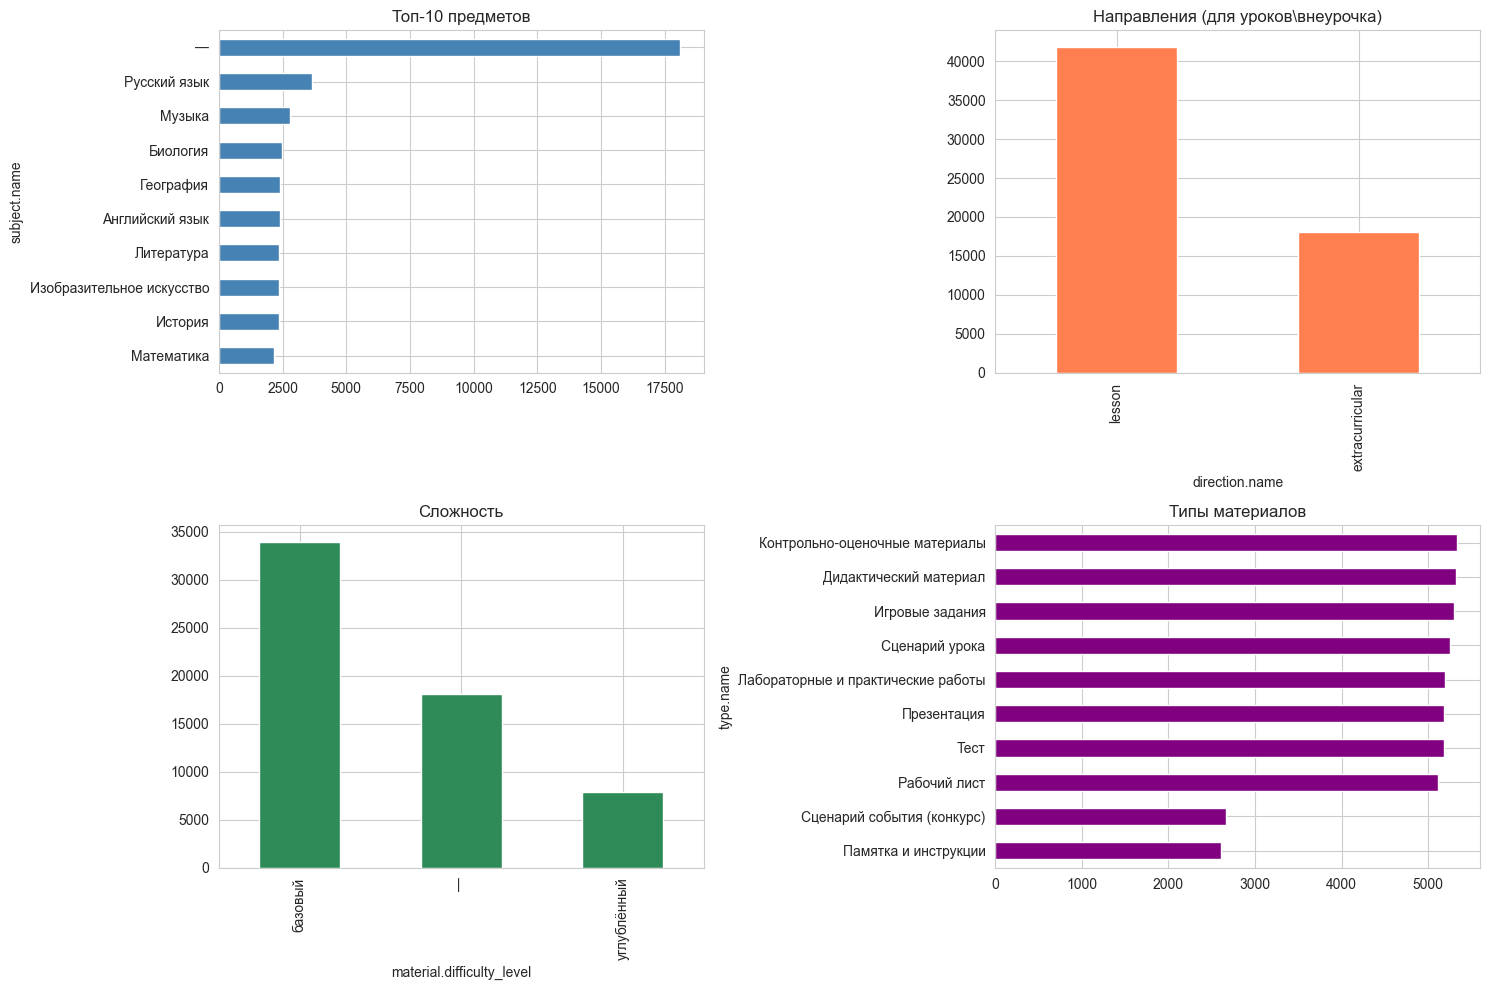

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

df['subject.name'].value_counts().head(10).plot(
    kind='barh', ax=axes[0, 0], color='steelblue')
axes[0, 0].set_title('Топ-10 предметов')
axes[0, 0].invert_yaxis()

df['direction.name'].value_counts().plot(
    kind='bar', ax=axes[0, 1], color='coral')
axes[0, 1].set_title('Направления (для уроков\внеурочка)')

df['material.difficulty_level'].value_counts().plot(
    kind='bar', ax=axes[1, 0], color='seagreen')
axes[1, 0].set_title('Сложность')

df['type.name'].value_counts().head(10).plot(
    kind='barh', ax=axes[1, 1], color='purple')
axes[1, 1].set_title('Типы материалов')
axes[1, 1].invert_yaxis()

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'eda_overview.png', dpi=100, bbox_inches='tight')
plt.show()

In [7]:
# сборка текста для моделей
def build_text(row) -> str:
    parts = []

    # Название и описания
    for col in ['material.title', 'material.description', 'material.content']:
        v = row.get(col)
        if isinstance(v, str) and v.strip() and v.strip() != '—':
            parts.append(v)

    # Тема и раздел — самые информативные
    for col in ['theme.name', 'section.name', 'module.name', 'subject.name']:
        v = row.get(col)
        if isinstance(v, str) and v.strip() and v.strip() != '—':
            parts.append(v)

    # Тип, сложность, формат
    for col in ['type.name', 'material.difficulty_level',
                'task.name', 'presentation_form', 'material.author_purpose',
                'format', 'umk.name']:
        v = row.get(col)
        if isinstance(v, str) and v.strip() and v.strip() != '—':
            parts.append(v)

    # Мульти-списки
    parts.extend(row.get('file_types', ()))
    parts.extend(row.get('work_forms', ()))

    return ' '.join(parts).strip()


df['full_text'] = df.apply(build_text, axis=1)

print(f"Средняя длина: {df['full_text'].str.len().mean():.0f}")
print(f"Пустых: {(df['full_text'].str.len() == 0).sum()}")
print("\nПример:")
print(df['full_text'].iloc[0][:400])

Средняя длина: 401
Пустых: 0

Пример:
Сценарий урока «Музыка стран дальнего зарубежья» Пошаговый сценарий урока по теме: Музыка стран дальнего зарубежья Введение, практика, рефлексия Музыка стран дальнего зарубежья: музыка Испании и Латинской Америки; фламенко; искусство игры на гитаре, кастаньеты, латиноамериканские ударные инструменты; танцевальные жанры Музыка стран дальнего зарубежья: музыка народов Европы; танцевальный и песенный


In [8]:
# Лемматизация

morph = pymorphy3.MorphAnalyzer()

RU_STOP = set(stopwords.words('russian'))
RU_STOP |= {
    'материал', 'занятие', 'урок', 'класс', 'работа', 'задание',
    'использование', 'помощь', 'помощью', 'также', 'который',
    'может', 'подходит', 'включает', 'содержит',
    'тема', 'тип', 'уроки', 'занятия', 'классы',
}
_PUNCT_RE = re.compile(r'[^а-яёa-z0-9\s]', re.IGNORECASE)


def preprocess(text: str) -> str:
    if not isinstance(text, str) or not text:
        return ''
    text = text.lower()
    text = _PUNCT_RE.sub(' ', text)
    tokens = [t for t in text.split() if len(t) > 2 and t not in RU_STOP]
    tokens = [morph.parse(t)[0].normal_form for t in tokens]
    return ' '.join(tokens)


tqdm.pandas(desc='Lemmatize')
df['clean_text'] = df['full_text'].progress_apply(preprocess)
print(f"Непустых: {(df['clean_text'].str.len() > 0).sum()}/{len(df)}")

Lemmatize:   0%|          | 0/60000 [00:00<?, ?it/s]

Непустых: 60000/60000


In [9]:
# TF-IDF
tfidf = TfidfVectorizer(
    max_features=15000,
    min_df=2,
    max_df=0.95,
    ngram_range=(1, 2),
    sublinear_tf=True,
)
tfidf_matrix = tfidf.fit_transform(df['clean_text'])

print(f"TF-IDF: {tfidf_matrix.shape}")
print(f"nnz: {tfidf_matrix.nnz:,}")

# топ-слов
feat = tfidf.get_feature_names_out()
mean_tfidf = np.asarray(tfidf_matrix.mean(axis=0)).flatten()
for idx in np.argsort(-mean_tfidf)[:15]:
    print(f"  {feat[idx]}: {mean_tfidf[idx]:.4f}")

with open(OUTPUT_DIR / 'tfidf.pkl', 'wb') as f:
    pickle.dump(tfidf, f)

TF-IDF: (60000, 15000)
nnz: 3,086,006
  сценарий: 0.0248
  печать: 0.0227
  задание: 0.0209
  цифровой: 0.0191
  практический: 0.0186
  групповой: 0.0180
  парный: 0.0179
  навык: 0.0170
  развить: 0.0169
  базовый: 0.0167
  инструкция: 0.0166
  проект: 0.0155
  печать цифровой: 0.0151
  конкурс: 0.0148
  знание: 0.0148


In [10]:
# TF-IDF top-K батчами
TOP_K = 50
BATCH = 512
N = df.shape[0]

tfidf_idx   = np.zeros((N, TOP_K), dtype=np.int32)
tfidf_score = np.zeros((N, TOP_K), dtype=np.float32)

for start in range(0, N, BATCH):
    end = min(start + BATCH, N)
    block = cosine_similarity(tfidf_matrix[start:end], tfidf_matrix)

    # исключаем самого себя
    for li, gi in enumerate(range(start, end)):
        block[li, gi] = 0.0

    part = np.argpartition(-block, TOP_K, axis=1)[:, :TOP_K]
    for li in range(end - start):
        ids = part[li]
        order = np.argsort(-block[li, ids])
        tfidf_idx[start + li]   = ids[order]
        tfidf_score[start + li] = block[li, ids[order]]
    del block

print(f"TF-IDF top-1 mean: {tfidf_score[:, 0].mean():.4f}")
np.save(OUTPUT_DIR / 'tfidf_top_idx.npy',   tfidf_idx)
np.save(OUTPUT_DIR / 'tfidf_top_score.npy', tfidf_score)

TF-IDF top-1 mean: 0.8526


In [11]:
# Semantic эмбеддинги
MODEL_NAME = 'cointegrated/rubert-tiny2'
st = SentenceTransformer(MODEL_NAME)

emb = st.encode(
    df['clean_text'].tolist(),
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True,
)
print(f"Embeddings: {emb.shape}")
np.save(OUTPUT_DIR / 'embeddings.npy', emb)

Loading weights:   0%|          | 0/55 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: cointegrated/rubert-tiny2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Batches:   0%|          | 0/1875 [00:00<?, ?it/s]

Embeddings: (60000, 312)


In [12]:
# Semantic top-K батчами
sem_idx   = np.zeros((N, TOP_K), dtype=np.int32)
sem_score = np.zeros((N, TOP_K), dtype=np.float32)

for start in range(0, N, BATCH):
    end = min(start + BATCH, N)
    block = emb[start:end] @ emb.T
    for li, gi in enumerate(range(start, end)):
        block[li, gi] = 0.0

    part = np.argpartition(-block, TOP_K, axis=1)[:, :TOP_K]
    for li in range(end - start):
        ids = part[li]
        order = np.argsort(-block[li, ids])
        sem_idx[start + li]   = ids[order]
        sem_score[start + li] = block[li, ids[order]]
    del block

print(f"Semantic top-1 mean: {sem_score[:, 0].mean():.4f}")
np.save(OUTPUT_DIR / 'sem_top_idx.npy',   sem_idx)
np.save(OUTPUT_DIR / 'sem_top_score.npy', sem_score)

Semantic top-1 mean: 0.9737


In [13]:
# подготовка для построения матрицы сходства

SAMPLE_N = 2000
np.random.seed(SEED)
sample_idx = np.random.choice(len(df), size=min(SAMPLE_N, len(df)), replace=False)

print(f"Сэмпл: {len(sample_idx)} материалов из {len(df)}")

# TF-IDF (разреженная → плотная на сэмпле)
tfidf_similarity = (
    tfidf_matrix[sample_idx] @ tfidf_matrix[sample_idx].T
).toarray()

# Semantic (плотная, уже нормализованная)
semantic_similarity = emb[sample_idx] @ emb[sample_idx].T

print(f"tfidf_similarity:    {tfidf_similarity.shape}")
print(f"semantic_similarity: {semantic_similarity.shape}")

Сэмпл: 2000 материалов из 60000
tfidf_similarity:    (2000, 2000)
semantic_similarity: (2000, 2000)


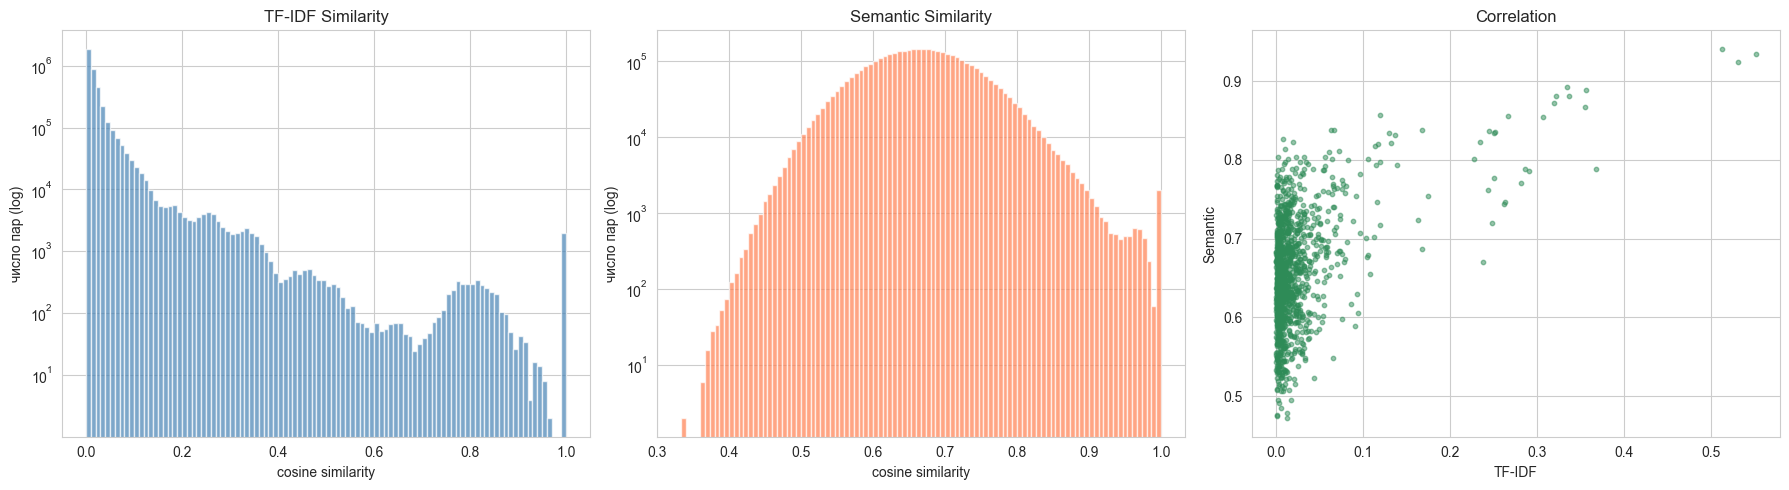

Корреляция: 0.4680

Пересечение top-K (доля общих рекомендаций):
  @ 5: 0.518
  @10: 0.521
  @20: 0.513
  @50: 0.536


In [14]:
# СРАВНЕНИЕ: TF-IDF vs Semantic 

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# TF-IDF
axes[0].hist(tfidf_similarity.flatten(), bins=100, color='steelblue', alpha=0.7)
axes[0].set_title('TF-IDF Similarity')
axes[0].set_xlabel('cosine similarity')
axes[0].set_ylabel('число пар (log)')
axes[0].set_yscale('log')

# Semantic
axes[1].hist(semantic_similarity.flatten(), bins=100, color='coral', alpha=0.7)
axes[1].set_title('Semantic Similarity')
axes[1].set_xlabel('cosine similarity')
axes[1].set_ylabel('число пар (log)')
axes[1].set_yscale('log')

# TF-IDF vs Semantic
n = len(sample_idx)                    # размер сэмпла, а не len(df)!
sample_i = np.random.choice(n, size=min(50, n), replace=False)
pairs = []
for i in sample_i:
    for j in sample_i:
        if i < j:
            pairs.append((tfidf_similarity[i, j], semantic_similarity[i, j]))
pairs = np.array(pairs)

if len(pairs) > 0:
    axes[2].scatter(pairs[:, 0], pairs[:, 1], alpha=0.5, s=10, color='seagreen')
axes[2].set_xlabel('TF-IDF')
axes[2].set_ylabel('Semantic')
axes[2].set_title('Correlation')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'similarity_comparison.png', dpi=100, bbox_inches='tight')
plt.show()

if len(pairs) > 0:
    corr = np.corrcoef(pairs[:, 0], pairs[:, 1])[0, 1]
    print(f"Корреляция: {corr:.4f}")


# Дополнительно: пересечение top-K
def overlap_at_k(idx_a, idx_b, k=10):
    ov = [len(set(idx_a[i, :k]) & set(idx_b[i, :k])) / k for i in range(len(idx_a))]
    return np.mean(ov)

print()
print("Пересечение top-K (доля общих рекомендаций):")
for k in [5, 10, 20, 50]:
    ov = overlap_at_k(tfidf_idx, sem_idx, k=k)
    print(f"  @{k:2d}: {ov:.3f}")

In [15]:
# Hybrid подбор α
def make_hybrid(tfidf_i, tfidf_s, sem_i, sem_s, alpha, K=TOP_K):
    N = tfidf_i.shape[0]
    hidx = np.zeros((N, K), dtype=np.int32)
    hscr = np.zeros((N, K), dtype=np.float32)

    for i in tqdm(range(N), desc=f'Hybrid α={alpha:.1f}'):
        td = dict(zip(tfidf_i[i], tfidf_s[i]))
        sd = dict(zip(sem_i[i],   sem_s[i]))

        cand = [c for c in (set(td) | set(sd)) if c != i]
        if not cand:
            continue
        cand = np.asarray(cand, dtype=np.int32)
        t = np.array([td.get(c, 0.0) for c in cand], dtype=np.float32)
        s = np.array([sd.get(c, 0.0) for c in cand], dtype=np.float32)

        hs = alpha * t + (1 - alpha) * s
        order = np.argsort(-hs)[:K]
        hidx[i] = cand[order]
        hscr[i] = hs[order]
    return hidx, hscr

In [16]:
# Ground truth (по двум пространствам отдельно)
# признаки для релевантности
REL_CODES_COLS = [
    'theme.name', 'section.name', 'module.name',
    'type.name', 'material.difficulty_level',
]
rel_codes = {c: pd.factorize(df[c].astype(str))[0] for c in REL_CODES_COLS}

# work_forms — мульти, кодируем как битовые маски по всем уникальным значениям
all_wf = sorted({w for ws in df['work_forms'] for w in ws})
wf_to_idx = {w: i for i, w in enumerate(all_wf)}
wf_mask = np.zeros((len(df), len(all_wf)), dtype=bool)
for i, ws in enumerate(df['work_forms']):
    for w in ws:
        wf_mask[i, wf_to_idx[w]] = True

# file_types — аналогично
all_ft = sorted({f for fs in df['file_types'] for f in fs})
ft_to_idx = {f: i for i, f in enumerate(all_ft)}
ft_mask = np.zeros((len(df), len(all_ft)), dtype=bool)
for i, fs in enumerate(df['file_types']):
    for f in fs:
        ft_mask[i, ft_to_idx[f]] = True

WEIGHTS = {
    'same_theme':      3.0,   # совпадение theme.name
    'same_section':    2.0,
    'same_module':     1.0,
    'same_type':       1.5,
    'same_difficulty': 1.0,
    'grade_overlap':   2.0,   # пересечение grade_set
    'work_form_overlap': 0.5,
    'file_type_overlap': 0.3,
}

# Группировка
def build_group_key(row) -> str:
    direc = row['direction.name']
    subj  = row['subject.name']
    theme = row['theme.name']

    # Внеурочка без предмета → группируем по теме
    if direc == 'extracurricular' and subj == '—':
        if theme == '—' or not theme:
            return 'EXTRA::_other'
        return 'EXTRA::' + theme
    # Обычные предметные
    if subj != '—':
        return 'SUBJ::' + subj
    # остальное — отдельная группа
    return 'OTHER::' + (theme if theme != '—' else '_other')

df['group_key'] = df.apply(build_group_key, axis=1)
group_codes = pd.factorize(df['group_key'])[0]
group_members = {}
for i, c in enumerate(group_codes):
    group_members.setdefault(c, []).append(i)
group_members = {k: np.asarray(v) for k, v in group_members.items()}

print(f"Всего групп: {len(group_members)}")
sizes = sorted((len(v) for v in group_members.values()), reverse=True)
print(f"Топ-5 размеров: {sizes[:5]}")
print(f"Групп размера 1: {sum(1 for x in sizes if x == 1)}")
print(f"Групп размера <5: {sum(1 for x in sizes if x < 5)}")


def group_by_prefix(prefix):
    return [k for k, v in group_members.items() if df['group_key'].iloc[v[0]].startswith(prefix)]
print(f"SUBJ групп: {len(group_by_prefix('SUBJ::'))}")
print(f"EXTRA групп: {len(group_by_prefix('EXTRA::'))}")
print(f"OTHER групп: {len(group_by_prefix('OTHER::'))}")

# Предвычислим сет grade и маски
grade_sets = df['grade_set'].tolist()  # list of frozenset


def relevance_scores(i, cand: np.ndarray) -> np.ndarray:
    scores = np.zeros(len(cand), dtype=np.float32)

    # theme, section, module, type, difficulty
    scores += (rel_codes['theme.name'][cand] == rel_codes['theme.name'][i]) * WEIGHTS['same_theme']
    scores += (rel_codes['section.name'][cand] == rel_codes['section.name'][i]) * WEIGHTS['same_section']
    scores += (rel_codes['module.name'][cand] == rel_codes['module.name'][i]) * WEIGHTS['same_module']
    scores += (rel_codes['type.name'][cand] == rel_codes['type.name'][i]) * WEIGHTS['same_type']
    scores += (rel_codes['material.difficulty_level'][cand] == rel_codes['material.difficulty_level'][i]) * WEIGHTS['same_difficulty']

    # grade_overlap: есть ли пересечение множеств
    gi = grade_sets[i]
    if gi:
        for pos, j in enumerate(cand):
            if grade_sets[j] & gi:
                scores[pos] += WEIGHTS['grade_overlap']

    # work_form: пересечение масок
    inter_wf = wf_mask[cand] & wf_mask[i]
    scores += inter_wf.any(axis=1).astype(np.float32) * WEIGHTS['work_form_overlap']

    # file_type: пересечение масок
    inter_ft = ft_mask[cand] & ft_mask[i]
    scores += inter_ft.any(axis=1).astype(np.float32) * WEIGHTS['file_type_overlap']

    return scores


def build_ground_truth(threshold: float, top_k: int = 20) -> dict:
    gt = {}
    for i in tqdm(range(len(df)), desc=f'GT thr={threshold}'):
        members = group_members[group_codes[i]]
        cand = members[members != i]
        if len(cand) == 0:
            gt[i] = []
            continue

        scores = relevance_scores(i, cand)
        mask = scores >= threshold
        c, s = cand[mask], scores[mask]
        if len(c) == 0:
            gt[i] = []
            continue

        if len(c) > top_k:
            c = c[np.argsort(-s)[:top_k]]
        gt[i] = [int(x) for x in c]
    return gt


gt_easy   = build_ground_truth(threshold=3.0)
gt_medium = build_ground_truth(threshold=5.0)
gt_hard   = build_ground_truth(threshold=7.0)

for name, gt in [('easy', gt_easy), ('medium', gt_medium), ('hard', gt_hard)]:
    with_rel = sum(1 for v in gt.values() if v)
    avg = np.mean([len(v) for v in gt.values()])
    print(f"{name}: с релевантными={with_rel}/{len(gt)}, avg={avg:.1f}")

for name, gt in [('easy', gt_easy), ('medium', gt_medium), ('hard', gt_hard)]:
    with open(OUTPUT_DIR / f'gt_{name}.json', 'w') as f:
        json.dump({str(k): v for k, v in gt.items()}, f)

Всего групп: 42
Топ-5 размеров: [3659, 2772, 2488, 2415, 2407]
Групп размера 1: 0
Групп размера <5: 0
SUBJ групп: 24
EXTRA групп: 18
OTHER групп: 0


GT thr=3.0:   0%|          | 0/60000 [00:00<?, ?it/s]

GT thr=5.0:   0%|          | 0/60000 [00:00<?, ?it/s]

GT thr=7.0:   0%|          | 0/60000 [00:00<?, ?it/s]

easy: с релевантными=60000/60000, avg=20.0
medium: с релевантными=60000/60000, avg=19.8
hard: с релевантными=59304/60000, avg=11.6


In [17]:
# метрики
def precision_at_k(recs, rel, k):
    if k <= 0:
        return 0.0
    top = recs[:k]
    return len(set(top) & set(rel)) / k


def recall_at_k(recs, rel, k):
    if not rel:
        return 0.0
    top = recs[:k]
    return len(set(top) & set(rel)) / len(rel)


def ndcg_at_k(recs, rel, k):
    top = recs[:k]
    rel_set = set(rel)
    dcg = sum(1.0 / np.log2(r + 1) for r, it in enumerate(top, 1) if it in rel_set)
    idcg = sum(1.0 / np.log2(r + 1) for r in range(1, min(len(rel), k) + 1))
    return dcg / idcg if idcg > 0 else 0.0


def evaluate(top_idx: np.ndarray, gt: dict, k: int = 10,
             subset_mask: np.ndarray = None) -> dict:
    prec, rec, ndcg = [], [], []
    for i, rel in gt.items():
        if not rel:
            continue
        if subset_mask is not None and not subset_mask[i]:
            continue
        recs = [int(x) for x in top_idx[i][:k + 1] if x != i][:k]
        prec.append(precision_at_k(recs, rel, k))
        rec.append(recall_at_k(recs, rel, k))
        ndcg.append(ndcg_at_k(recs, rel, k))

    n = len(prec)
    return {
        f'P@{k}':    float(np.mean(prec)) if n else 0.0,
        f'R@{k}':    float(np.mean(rec))  if n else 0.0,
        f'NDCG@{k}': float(np.mean(ndcg)) if n else 0.0,
        'N':         n,
    }

In [18]:
# Оценка TF-IDF и Semantic
is_extra  = df['group_key'].str.startswith('EXTRA::').values
is_subj   = df['group_key'].str.startswith('SUBJ::').values
is_other  = df['group_key'].str.startswith('OTHER::').values

subsets = [
    ('all',             None),
    ('subjects',        is_subj),
    ('extracurricular', is_extra),
    ('other',           is_other),
]

rows = []
for mode, gt in [('easy', gt_easy), ('medium', gt_medium), ('hard', gt_hard)]:
    for sname, mask in subsets:
        for mname, top_idx in [('TF-IDF', tfidf_idx), ('Semantic', sem_idx)]:
            m = evaluate(top_idx, gt, k=10, subset_mask=mask)
            rows.append({'Mode': mode, 'Subset': sname, 'Model': mname, **m})

res_df = pd.DataFrame(rows)
print(res_df.to_string(index=False))
res_df.to_csv(OUTPUT_DIR / 'results.csv', index=False)

  Mode          Subset    Model     P@10     R@10  NDCG@10     N
  easy             all   TF-IDF 0.543502 0.271751 0.584445 60000
  easy             all Semantic 0.455847 0.227923 0.503945 60000
  easy        subjects   TF-IDF 0.709179 0.354590 0.765839 41878
  easy        subjects Semantic 0.566008 0.283004 0.632433 41878
  easy extracurricular   TF-IDF 0.160639 0.080320 0.165263 18122
  easy extracurricular Semantic 0.201275 0.100637 0.207024 18122
  easy           other   TF-IDF 0.000000 0.000000 0.000000     0
  easy           other Semantic 0.000000 0.000000 0.000000     0
medium             all   TF-IDF 0.543092 0.275075 0.584351 60000
medium             all Semantic 0.455340 0.230045 0.503667 60000
medium        subjects   TF-IDF 0.708592 0.359351 0.765704 41878
medium        subjects Semantic 0.565282 0.286044 0.632034 41878
medium extracurricular   TF-IDF 0.160639 0.080320 0.165263 18122
medium extracurricular Semantic 0.201275 0.100637 0.207024 18122
medium           other   

Hybrid α=0.0:   0%|          | 0/60000 [00:00<?, ?it/s]

Hybrid α=0.1:   0%|          | 0/60000 [00:00<?, ?it/s]

Hybrid α=0.2:   0%|          | 0/60000 [00:00<?, ?it/s]

Hybrid α=0.3:   0%|          | 0/60000 [00:00<?, ?it/s]

Hybrid α=0.4:   0%|          | 0/60000 [00:00<?, ?it/s]

...

Hybrid α=0.7:   0%|          | 0/60000 [00:00<?, ?it/s]

Hybrid α=0.8:   0%|          | 0/60000 [00:00<?, ?it/s]

Hybrid α=0.9:   0%|          | 0/60000 [00:00<?, ?it/s]

Hybrid α=1.0:   0%|          | 0/60000 [00:00<?, ?it/s]

 alpha     P@10     R@10  NDCG@10     N
   0.0 0.455340 0.230045 0.503671 60000
   0.1 0.511918 0.258834 0.557831 60000
   0.2 0.520297 0.263138 0.566525 60000
   0.3 0.522967 0.264512 0.569207 60000
   0.4 0.523772 0.264938 0.570069 60000
   0.5 0.524043 0.265082 0.570378 60000
   0.6 0.524748 0.265438 0.570857 60000
   0.7 0.527360 0.266799 0.572656 60000
   0.8 0.530900 0.268644 0.575247 60000
   0.9 0.538980 0.272847 0.581454 60000
   1.0 0.543092 0.275075 0.584354 60000

Best α = 1.0


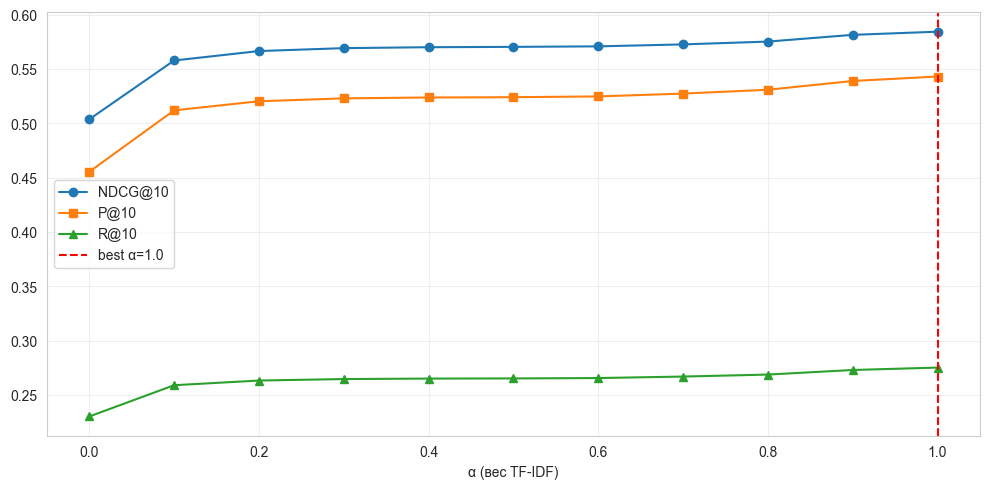

In [20]:
# Подбор α для Hybrid
alphas = np.round(np.arange(0.0, 1.01, 0.1), 2)
alpha_rows = []

for a in alphas:
    h_idx, h_score = make_hybrid(tfidf_idx, tfidf_score, sem_idx, sem_score, alpha=a)
    m = evaluate(h_idx, gt_medium, k=10)
    alpha_rows.append({'alpha': float(a), **m})

alpha_df = pd.DataFrame(alpha_rows)
print(alpha_df.to_string(index=False))

best_alpha = float(alpha_df.loc[alpha_df['NDCG@10'].idxmax(), 'alpha'])
print(f"\nBest α = {best_alpha}")

alpha_df.to_csv(OUTPUT_DIR / 'alpha_search.csv', index=False)

plt.figure(figsize=(10, 5))
for col, marker in [('NDCG@10', 'o'), ('P@10', 's'), ('R@10', '^')]:
    plt.plot(alpha_df['alpha'], alpha_df[col], marker + '-', label=col)
plt.axvline(best_alpha, color='red', linestyle='--', label=f'best α={best_alpha}')
plt.xlabel('α (вес TF-IDF)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'alpha_curve.png', dpi=100)
plt.show()

Hybrid α=1.0:   0%|          | 0/60000 [00:00<?, ?it/s]

  Mode          Subset        Model     P@10     R@10  NDCG@10     N
  easy             all       TF-IDF 0.543502 0.271751 0.584445 60000
  easy             all     Semantic 0.455847 0.227923 0.503945 60000
  easy             all Hybrid α=1.0 0.543502 0.271751 0.584448 60000
  easy        subjects       TF-IDF 0.709179 0.354590 0.765839 41878
  easy        subjects     Semantic 0.566008 0.283004 0.632433 41878
  easy        subjects Hybrid α=1.0 0.709179 0.354590 0.765839 41878
  easy extracurricular       TF-IDF 0.160639 0.080320 0.165263 18122
  easy extracurricular     Semantic 0.201275 0.100637 0.207024 18122
  easy extracurricular Hybrid α=1.0 0.160639 0.080320 0.165273 18122
  easy           other       TF-IDF 0.000000 0.000000 0.000000     0
  easy           other     Semantic 0.000000 0.000000 0.000000     0
  easy           other Hybrid α=1.0 0.000000 0.000000 0.000000     0
medium             all       TF-IDF 0.543092 0.275075 0.584351 60000
medium             all     Semanti

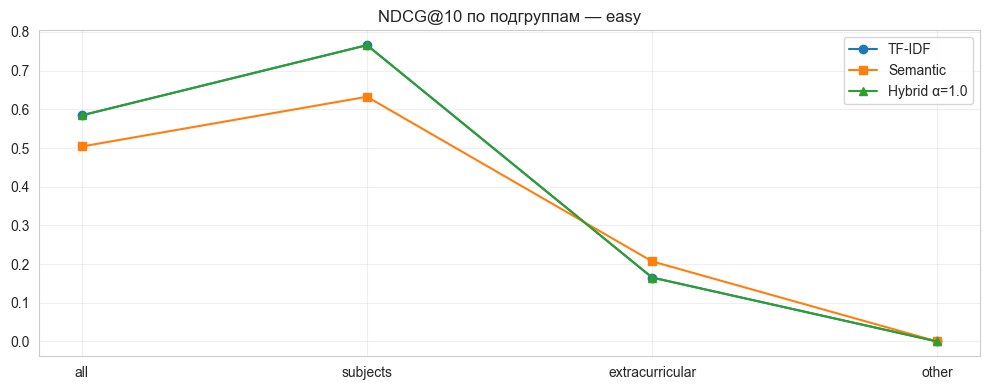

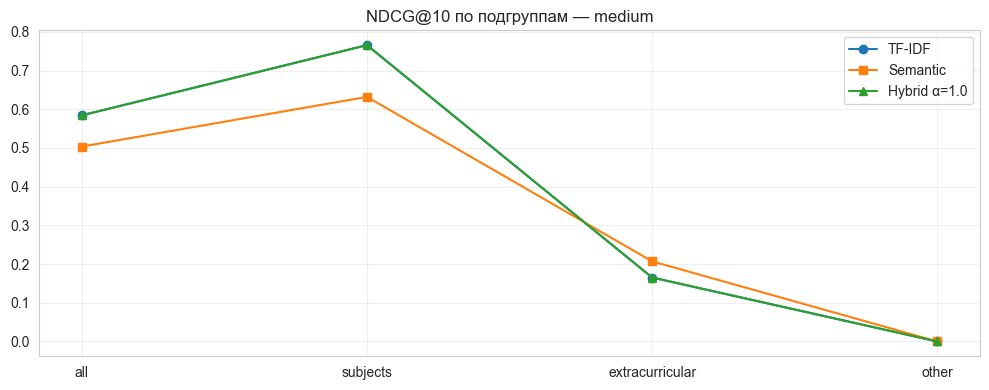

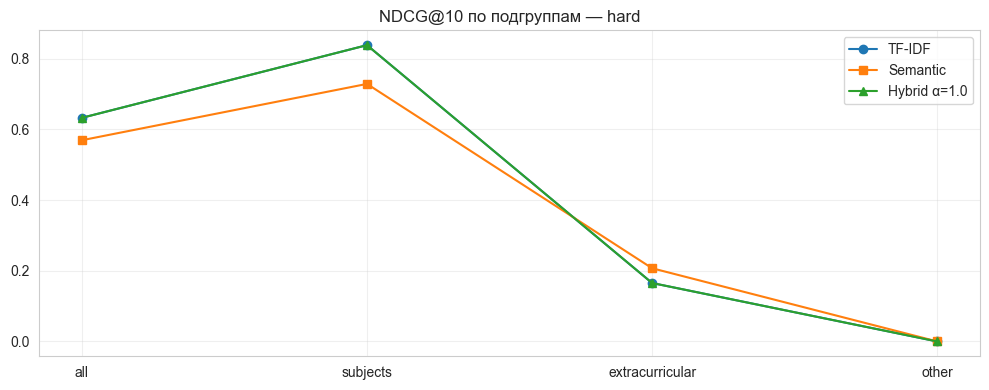

In [21]:
# итоговое сравнение
hybrid_idx, hybrid_score = make_hybrid(
    tfidf_idx, tfidf_score, sem_idx, sem_score, alpha=best_alpha
)
np.save(OUTPUT_DIR / 'hybrid_top_idx.npy',   hybrid_idx)
np.save(OUTPUT_DIR / 'hybrid_top_score.npy', hybrid_score)

final_rows = []
for mode, gt in [('easy', gt_easy), ('medium', gt_medium), ('hard', gt_hard)]:
    for sname, mask in subsets:
        for mname, top_idx in [
            ('TF-IDF', tfidf_idx),
            ('Semantic', sem_idx),
            (f'Hybrid α={best_alpha}', hybrid_idx),
        ]:
            m = evaluate(top_idx, gt, k=10, subset_mask=mask)
            final_rows.append({'Mode': mode, 'Subset': sname, 'Model': mname, **m})

final_df = pd.DataFrame(final_rows)
print(final_df.to_string(index=False))
final_df.to_csv(OUTPUT_DIR / 'final_comparison.csv', index=False)

# --- График по подгруппам ---
for mode in ['easy', 'medium', 'hard']:
    sub = final_df[final_df['Mode'] == mode]
    fig, ax = plt.subplots(figsize=(10, 4))
    x = np.arange(sub['Subset'].nunique())
    for i, (mname, marker) in enumerate([('TF-IDF', 'o'), ('Semantic', 's'),
                                         (f'Hybrid α={best_alpha}', '^')]):
        vals = sub[sub['Model'] == mname].set_index('Subset').reindex(
            [s for s, _ in subsets])['NDCG@10'].values
        ax.plot(x, vals, marker + '-', label=mname)
    ax.set_xticks(x)
    ax.set_xticklabels([s for s, _ in subsets])
    ax.set_title(f'NDCG@10 по подгруппам — {mode}')
    ax.legend()
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f'comparison_{mode}.png', dpi=100)
    plt.show()

In [22]:
# рекомендации
def show_recommendations(item_idx: int, top_idx, top_score, k=5, model_name='Model'):
    print(f"\n[{model_name}] для: {df['material.title'].iloc[item_idx][:80]}")
    print(f"  subject={df['subject.name'].iloc[item_idx]}, "
          f"direction={df['direction.name'].iloc[item_idx]}, "
          f"theme={df['theme.name'].iloc[item_idx][:60]}")
    for rank, (idx, sc) in enumerate(zip(top_idx[item_idx][:k],
                                          top_score[item_idx][:k]), 1):
        idx = int(idx)
        if idx == item_idx:
            continue
        print(f"   {rank}. [{sc:.3f}] {df['material.title'].iloc[idx][:70]}")


# три случайных примера из разных подгрупп
np.random.seed(SEED)
sample_subj = np.random.choice(np.where(is_subj)[0], 1)[0]
sample_extra = np.random.choice(np.where(is_extra)[0], 1)[0] if is_extra.any() else None

for idx in filter(None, [sample_subj, sample_extra]):
    show_recommendations(idx, tfidf_idx, tfidf_score, k=3, model_name='TF-IDF')
    show_recommendations(idx, sem_idx,   sem_score,   k=3, model_name='Semantic')
    show_recommendations(idx, hybrid_idx, hybrid_score, k=3, model_name='Hybrid')


[TF-IDF] для: Тест «Социальная и правовая модернизация страны при императоре…»
  subject=История, direction=lesson, theme=Социальная и правовая модернизация страны при императоре Але
   1. [0.859] Дидактические карточки «Социальная и правовая модернизация страны при 
   2. [0.844] Рабочий лист «Социальная и правовая модернизация страны при императоре
   3. [0.843] Контрольная работа «Социальная и правовая модернизация страны при импе

[Semantic] для: Тест «Социальная и правовая модернизация страны при императоре…»
  subject=История, direction=lesson, theme=Социальная и правовая модернизация страны при императоре Але
   1. [0.956] Контрольная работа «Социальная и правовая модернизация страны при импе
   2. [0.948] Сценарий урока «Социальная и правовая модернизация страны при императо
   3. [0.947] Рабочий лист «Социальная и правовая модернизация страны при императоре

[Hybrid] для: Тест «Социальная и правовая модернизация страны при императоре…»
  subject=История, direction=lesson, the

In [23]:
# анализ ошибок
def pair_relevance(i, j):
    if group_codes[i] != group_codes[j]:
        return 0.0
    return float(relevance_scores(i, np.asarray([j]))[0])


def find_hard_negatives(top_idx, top_score, sim_thr=0.5, rel_thr=5, n=5):
    hard = []
    sample = np.random.choice(len(df), size=min(2000, len(df)), replace=False)
    for i in tqdm(sample, desc='Hard negatives'):
        for j, s in zip(top_idx[i], top_score[i]):
            j = int(j)
            if s < sim_thr or i >= j:
                continue
            r = pair_relevance(i, j)
            if r < rel_thr:
                hard.append({'i': i, 'j': j, 'rel': r, 'sim': float(s)})
    hard.sort(key=lambda x: -x['sim'])
    return hard[:n]


print("HARD NEGATIVES (похожи, но нерелевантны):")
for k, hn in enumerate(find_hard_negatives(hybrid_idx, hybrid_score), 1):
    print(f"\n{k}. sim={hn['sim']:.3f}, rel={hn['rel']:.1f}")
    print(f"   A: {df['material.title'].iloc[hn['i']][:70]}")
    print(f"   B: {df['material.title'].iloc[hn['j']][:70]}")

HARD NEGATIVES (похожи, но нерелевантны):


Hard negatives:   0%|          | 0/2000 [00:00<?, ?it/s]


1. sim=0.935, rel=3.0
   A: Презентация «Родная страна и страна/страны изучаемого языка»
   B: Презентация «Родная страна и страна/страны изучаемого языка»

2. sim=0.932, rel=3.0
   A: Презентация «Родная страна и страна/страны изучаемого языка»
   B: Презентация «Родная страна и страна/страны изучаемого языка»

3. sim=0.932, rel=3.0
   A: Презентация «Родная страна и страна/страны изучаемого языка»
   B: Презентация «Родная страна и страна/страны изучаемого языка»

4. sim=0.927, rel=4.5
   A: Презентация «Опера»
   B: Дидактические карточки «Опера»

5. sim=0.926, rel=4.0
   A: Дидактические карточки «Музыка стран ближнего зарубежья»
   B: Игровые задания «Музыка стран ближнего зарубежья»


In [24]:
artifacts = {
    'df': df,
    'tfidf_vectorizer': tfidf,
    'tfidf_top_idx':    tfidf_idx,
    'tfidf_top_score':  tfidf_score,
    'sem_top_idx':      sem_idx,
    'sem_top_score':    sem_score,
    'hybrid_top_idx':   hybrid_idx,
    'hybrid_top_score': hybrid_score,
    'best_alpha':       best_alpha,
    'gt_easy':          gt_easy,
    'gt_medium':        gt_medium,
    'gt_hard':          gt_hard,
    'weights':          WEIGHTS,
    'group_key':        df['group_key'].tolist(),
    'group_codes':      group_codes,
}
with open(OUTPUT_DIR / 'recommender.pkl', 'wb') as f:
    pickle.dump(artifacts, f)

print(f"Сохранено в {OUTPUT_DIR}")
for p in sorted(OUTPUT_DIR.iterdir()):
    print(f"  {p.name:40s} {p.stat().st_size/1024:8.1f} KB")

Сохранено в output
  alpha_curve.png                              32.7 KB
  alpha_search.csv                              0.7 KB
  comparison_easy.png                          41.5 KB
  comparison_hard.png                          38.2 KB
  comparison_medium.png                        41.2 KB
  eda_overview.png                             86.5 KB
  embeddings.npy                            73125.1 KB
  extra_comparison.png                         19.7 KB
  extra_top_idx.npy                         11718.9 KB
  extra_top_score.npy                       11718.9 KB
  final_comparison.csv                          2.7 KB
  final_comparison.png                         32.4 KB
  gt_easy.json                               8634.4 KB
  gt_hard.json                               5290.6 KB
  gt_medium.json                             8544.4 KB
  hybrid_alpha.csv                              0.8 KB
  hybrid_alpha.png                             40.7 KB
  hybrid_top_idx.npy                        11

In [ ]:
# ЭКСПЕРИМЕНТ A vs B: убрать категории из текста

# A: baseline (текст + категории)
def build_text_A(row):
    parts = []
    for col in ['material.title', 'material.description', 'material.content',
                'theme.name', 'type.name', 'material.difficulty_level']:
        v = row.get(col)
        if isinstance(v, str) and v.strip() and v.strip() != '—':
            parts.append(v)
    return ' '.join(parts).strip()

# --- B: только текст ---
def build_text_B(row):
    parts = []
    for col in ['material.title', 'material.description', 'material.content']:
        v = row.get(col)
        if isinstance(v, str) and v.strip() and v.strip() != '—':
            parts.append(v)
    return ' '.join(parts).strip()

df['text_A'] = df.apply(build_text_A, axis=1)
df['text_B'] = df.apply(build_text_B, axis=1)

# TF-IDF + embeddings для A
tfidf_A = TfidfVectorizer(max_features=15000, ngram_range=(1, 2), sublinear_tf=True)
matrix_A = tfidf_A.fit_transform(df['text_A'])

st = SentenceTransformer('cointegrated/rubert-tiny2')
emb_A = st.encode(df['text_A'].tolist(), batch_size=32,
                  show_progress_bar=True, normalize_embeddings=True,
                  convert_to_numpy=True)

# TF-IDF + embeddings для B
tfidf_B = TfidfVectorizer(max_features=15000, ngram_range=(1, 2), sublinear_tf=True)
matrix_B = tfidf_B.fit_transform(df['text_B'])

emb_B = st.encode(df['text_B'].tolist(), batch_size=32,
                  show_progress_bar=True, normalize_embeddings=True,
                  convert_to_numpy=True)

# top-K для всех
def topk(matrix, is_sparse=True, k=50):
    idx = np.zeros((N, k), dtype=np.int32)
    score = np.zeros((N, k), dtype=np.float32)
    for start in range(0, N, 512):
        end = min(start + 512, N)
        block = cosine_similarity(matrix[start:end], matrix) if is_sparse \
                else matrix[start:end] @ matrix.T
        for li, gi in enumerate(range(start, end)):
            block[li, gi] = 0
        part = np.argpartition(-block, k, axis=1)[:, :k]
        for li in range(end - start):
            ids = part[li]
            order = np.argsort(-block[li, ids])
            idx[start + li]   = ids[order]
            score[start + li] = block[li, ids[order]]
    return idx, score

tfidf_A_idx, _ = topk(matrix_A, True)
sem_A_idx,   _ = topk(emb_A,   False)
tfidf_B_idx, _ = topk(matrix_B, True)
sem_B_idx,   _ = topk(emb_B,   False)

# Сравнение на одном и том же GT (gt_medium уже существует)
print("ЭКСПЕРИМЕНТ A vs B (NDCG@10, medium)")
print(f"{'Model':<12} {'A (всё)':>10} {'B (текст)':>10} {'Δ':>10}")
print("-" * 45)
for name, idx_A, idx_B in [
    ('TF-IDF',   tfidf_A_idx, tfidf_B_idx),
    ('Semantic', sem_A_idx,   sem_B_idx),
]:
    m_A = evaluate(idx_A, gt_medium, k=10)['NDCG@10']
    m_B = evaluate(idx_B, gt_medium, k=10)['NDCG@10']
    print(f"{name:<12} {m_A:>10.4f} {m_B:>10.4f} {m_B - m_A:>+10.4f}")

Loading weights:   0%|          | 0/55 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: cointegrated/rubert-tiny2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Batches:   0%|          | 0/1875 [00:00<?, ?it/s]

Batches:   0%|          | 0/1875 [00:00<?, ?it/s]

ЭКСПЕРИМЕНТ A vs B (NDCG@10, medium)
Model           A (всё)  B (текст)          Δ
---------------------------------------------
TF-IDF           0.4369     0.3927    -0.0442
Semantic         0.3667     0.2718    -0.0949


In [ ]:
# ПРОВЕРКА GT

# 1. Сколько релевантных на объект в каждом режиме
print("РАЗМЕР GT ПО РЕЖИМАМ")
for name, gt in [('easy', gt_easy), ('medium', gt_medium), ('hard', gt_hard)]:
    lens = [len(v) for v in gt.values()]
    print(f"{name:8s}: avg={np.mean(lens):.2f}, "
          f"max={max(lens)}, "
          f"объектов с rel={sum(1 for l in lens if l)}/{len(lens)}")

# 2. Совпадают ли GT easy и medium
def jaccard(gt_a, gt_b):
    js = []
    for i in gt_a:
        a, b = set(gt_a[i]), set(gt_b.get(i, []))
        if a or b:
            js.append(len(a & b) / len(a | b))
    return np.mean(js)

print(f"\nJaccard easy↔medium: {jaccard(gt_easy, gt_medium):.4f}  "
      f"(если ≈1.0 — эталоны идентичны)")
print(f"Jaccard medium↔hard: {jaccard(gt_medium, gt_hard):.4f}")

# 3. P@10 и NDCG@10 по режимам — главная проверка
print("МЕТРИКИ ПО РЕЖИМАМ (TF-IDF baseline)")
print(f"{'Mode':<8} {'P@10':>8} {'R@10':>8} {'NDCG@10':>10}")
print("-" * 40)
for name, gt in [('easy', gt_easy), ('medium', gt_medium), ('hard', gt_hard)]:
    m = evaluate(tfidf_idx, gt, k=10)
    print(f"{name:<8} {m['P@10']:>8.4f} {m['R@10']:>8.4f} {m['NDCG@10']:>10.4f}")

РАЗМЕР GT ПО РЕЖИМАМ
easy    : avg=20.00, max=20, объектов с rel=60000/60000
medium  : avg=19.79, max=20, объектов с rel=60000/60000
hard    : avg=11.63, max=20, объектов с rel=59304/60000

Jaccard easy↔medium: 0.8467  (если ≈1.0 — эталоны идентичны)
Jaccard medium↔hard: 0.5787
МЕТРИКИ ПО РЕЖИМАМ (TF-IDF baseline)
Mode         P@10     R@10    NDCG@10
----------------------------------------
easy       0.5435   0.2718     0.5844
medium     0.5431   0.2751     0.5844
hard       0.4231   0.5481     0.6324


In [30]:
# СВОДКА A vs B

rows = []
for exp, t_idx, s_idx in [
    ('A (всё)',          tfidf_A_idx, sem_A_idx),
    ('B (только текст)', tfidf_B_idx, sem_B_idx),
]:
    for model, idx in [('TF-IDF', t_idx), ('Semantic', s_idx)]:
        for mode, gt in [('easy', gt_easy), ('medium', gt_medium), ('hard', gt_hard)]:
            m = evaluate(idx, gt, k=10)
            rows.append({'Exp': exp, 'Model': model, 'Mode': mode,
                         'P@10': m['P@10'], 'NDCG@10': m['NDCG@10']})

res = pd.DataFrame(rows)

# Компактная сводка по medium
print("СВОДКА (medium): A → B")
piv = res[res['Mode'] == 'medium'].pivot_table(
    index='Model', columns='Exp', values='NDCG@10')
piv['Δ (B-A)'] = piv['B (только текст)'] - piv['A (всё)']
print(piv.round(4).to_string())

res.to_csv(OUTPUT_DIR / 'A_vs_B.csv', index=False)

СВОДКА (medium): A → B
Exp       A (всё)  B (только текст)  Δ (B-A)
Model                                       
Semantic   0.3667            0.2718  -0.0949
TF-IDF     0.4369            0.3927  -0.0442
